# How assumptions narrow the effect region

## Regions Defined by Assumptions

A partially identified effect is represented by a set rather than one number. With supplied outcome limits $L$ and $U$, write the empirical identification region as

$$
\mathcal I(L,U)=[\underline\tau(L,U),\overline\tau(L,U)].
$$

The set $\mathcal I(L,U)$ contains every empirical average effect consistent with the observed outcomes, consistency, and the supplied limits. Changing $L$ or $U$ changes the assumption and therefore changes the set. It does not add new observations.

### Group Decomposition

Let $p$ be the treated fraction, $\bar Y_1^{\mathrm{obs}}$ the mean observed outcome among treated units, and $\bar Y_0^{\mathrm{obs}}$ the mean observed outcome among control units. The limits can be written as

$$
\underline\tau=p(\bar Y_1^{\mathrm{obs}}-U)+(1-p)(L-\bar Y_0^{\mathrm{obs}}),
$$

and

$$
\overline\tau=p(\bar Y_1^{\mathrm{obs}}-L)+(1-p)(U-\bar Y_0^{\mathrm{obs}}).
$$

These expressions separate the treated and control contributions. They also show that the observed group means determine the location of the interval, while the assumed outcome range determines its width.

#### Packages and notebook settings

In [ ]:
from pathlib import Path as _FigurePath
from sys import path as _figure_import_path

_figure_folder = _FigurePath.cwd()
_figure_root = next(
    folder for folder in (_figure_folder, *_figure_folder.parents)
    if (folder / "notebook_figures.py").is_file()
)
_figure_import_path.insert(0, str(_figure_root))
from notebook_figures import display_notebook_figure

from pathlib import Path
import itertools
import sys
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sensemakr
import statsmodels.api as sm
from IPython.display import HTML, display as _display

def display(value):
    module = value.__class__.__module__
    if module.startswith('pandas') and hasattr(value, '_repr_html_'):
        html = value._repr_html_()
        return _display(HTML('<div style="display:flex;justify-content:center;">' + html + '</div>'))
    return _display(value)
BOOK_ROOT = Path.cwd().parents[1]
if str(BOOK_ROOT) not in sys.path:
    sys.path.insert(0, str(BOOK_ROOT))
from book_support import ensure_dataset
FINANCIAL_ROOT = BOOK_ROOT
import RiskLabAI
from RiskLabAI.causal_factor_analysis import manski_ate_bounds
assert RiskLabAI.__version__ == '3.2.0'
FIGURES = BOOK_ROOT / 'outputs' / 'figures' / '05_partial_identification'
TABLES = BOOK_ROOT / 'outputs' / 'tables' / '05_partial_identification'
FIGURE_DATA = BOOK_ROOT / 'outputs' / 'figure_data' / '05_partial_identification'


#### Figure settings

In [ ]:
DATA_FILE = ensure_dataset(BOOK_ROOT, 'mpdta')
for directory in [FIGURES, TABLES, FIGURE_DATA]:
    directory.mkdir(parents=True, exist_ok=True)
PALETTE = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151'}
plt.rcParams.update({'font.family': 'DejaVu Serif', 'font.size': 11.5, 'figure.facecolor': PALETTE['background'], 'axes.facecolor': PALETTE['axes'], 'axes.edgecolor': PALETTE['text'], 'axes.labelcolor': PALETTE['text'], 'axes.titlecolor': PALETTE['text'], 'xtick.color': PALETTE['text'], 'ytick.color': PALETTE['text'], 'text.color': PALETTE['text'], 'grid.color': PALETTE['grid'], 'grid.linestyle': ':', 'legend.facecolor': PALETTE['axes'], 'legend.edgecolor': PALETTE['grid'], 'savefig.facecolor': PALETTE['background'], 'savefig.transparent': False, 'savefig.dpi': 300})
VAR_LOOKUP = {'year': 'Year', 'countyreal': 'County identifier', 'lpop': 'Log population', 'lemp': 'Log employment', 'first_treat': 'First treatment year', 'treat': 'Treatment indicator'}

def rendered_value(value):
    if pd.isna(value):
        return ''
    if isinstance(value, (bool, np.bool_)):
        return 'Pass' if bool(value) else 'Fail'
    if isinstance(value, (int, np.integer)):
        return f'{int(value):,}'
    if isinstance(value, (float, np.floating)):
        value = float(value)
        if value == 0:
            return '0'
        if value.is_integer():
            return f'{int(value):,}'
        if abs(value) < 0.0001 or abs(value) >= 1000000:
            return f'{value:.6g}'
        return f'{value:.6f}'.rstrip('0').rstrip('.')
    return str(value)



#### Table and figure formatting

In [ ]:
def rendered_frame(frame):
    return frame.apply(lambda column: column.map(rendered_value))

def save_table(frame, stem, caption, label, fit=False):
    shown = rendered_frame(frame)
    shown.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = shown.to_latex(index=False, escape=True, caption=caption, label=label, position='htbp')
    latex = latex.replace('\\begin{table}[htbp]', '\\begin{table}[htbp]\n\\centering', 1)
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')
    display(shown)
    return shown

def finish_axis(axis, grid=True):
    axis.spines['top'].set_visible(False)
    axis.spines['right'].set_visible(False)
    if grid:
        axis.grid(True, alpha=0.65)
    axis.set_axisbelow(True)

def save_figure(figure, stem):
    figure.savefig(FIGURES / f'{stem}.png', dpi=300, bbox_inches='tight', facecolor=PALETTE['background'], transparent=False)
    figure.savefig(FIGURES / f'{stem}.pdf', bbox_inches='tight', facecolor=PALETTE['background'], transparent=False)
    display_notebook_figure(figure)
    plt.close(figure)



#### County frame

In [ ]:
def county_frame():
    raw = pd.read_csv(DATA_FILE)
    employment = raw.pivot(index='countyreal', columns='year', values='lemp')
    population = raw.pivot(index='countyreal', columns='year', values='lpop')
    first_treatment = raw.groupby('countyreal')['first_treat'].first()
    frame = pd.DataFrame({'County identifier': employment.index, 'Treatment group': (first_treatment.reindex(employment.index).to_numpy() > 0).astype(int), 'Log employment in 2003': employment[2003].to_numpy(), 'Log employment in 2006': employment[2006].to_numpy(), 'Log employment in 2007': employment[2007].to_numpy(), 'Log population in 2003': population[2003].to_numpy()})
    frame['Employment change, 2003 to 2007'] = frame['Log employment in 2007'] - frame['Log employment in 2003']
    frame['Employment increased, 2006 to 2007'] = (frame['Log employment in 2007'] > frame['Log employment in 2006']).astype(int)
    return (raw, frame)

def partial_r2(restricted, expanded):
    return float(1 - expanded.ssr / restricted.ssr)



#### Assumption ledger for the chapter calculations

In [1]:
def scalar(value):
    return float(np.asarray(value).item())
notation = pd.DataFrame([{'Symbol': 'I(L,U)', 'Description': 'Identification region under supplied outcome limits'}, {'Symbol': 'p', 'Description': 'Fraction of units in the treated group'}, {'Symbol': 'Mean observed Y among treated', 'Description': 'Observed treated-group outcome mean'}, {'Symbol': 'Mean observed Y among control', 'Description': 'Observed control-group outcome mean'}, {'Symbol': 'Lower tau', 'Description': 'Lower endpoint of the empirical effect region'}, {'Symbol': 'Upper tau', 'Description': 'Upper endpoint of the empirical effect region'}])
save_table(notation, 'regions_notation', 'Notation for identification and sensitivity regions.', 'tab:cim5-regions-notation', fit=True)
ledger = pd.DataFrame([{'Calculation': 'Worst-case effect region', 'Supplied information': 'Consistency and finite outcome limits', 'Not supplied': 'Exchangeability and sampling distribution'}, {'Calculation': 'Regression sensitivity', 'Supplied information': 'Linear regression and two partial R-squared values', 'Not supplied': 'Identity or existence of an omitted variable'}, {'Calculation': 'Observed-covariate benchmark', 'Supplied information': 'Measured baseline variables', 'Not supplied': 'Upper bound on all hidden confounding'}, {'Calculation': 'Public county example', 'Supplied information': 'Fixed public outcomes and group labels', 'Not supplied': 'A defended causal assignment mechanism'}])
save_table(ledger, 'regions_assumption_ledger', 'Assumption ledger for the chapter calculations.', 'tab:cim5-regions-assumption-ledger', fit=True)
raw, counties = county_frame()
y_binary = counties['Employment increased, 2006 to 2007'].to_numpy()
d_public = counties['Treatment group'].to_numpy()
p = d_public.mean()
treated_mean = y_binary[d_public == 1].mean()
control_mean = y_binary[d_public == 0].mean()
lower_treated = p * (treated_mean - 1)
lower_control = (1 - p) * (0 - control_mean)
upper_treated = p * treated_mean
upper_control = (1 - p) * (1 - control_mean)
decomposition = pd.DataFrame([{'Endpoint': 'Lower', 'Treated contribution': lower_treated, 'Control contribution': lower_control, 'Total': lower_treated + lower_control}, {'Endpoint': 'Upper', 'Treated contribution': upper_treated, 'Control contribution': upper_control, 'Total': upper_treated + upper_control}])
released_binary = manski_ate_bounds(y_binary, d_public, lower=0, upper=1)
assert np.isclose(decomposition.loc[0, 'Total'], released_binary['lower'])
assert np.isclose(decomposition.loc[1, 'Total'], released_binary['upper'])
save_table(decomposition, 'regions_public_bound_decomposition', 'Treated and control contributions to the public binary-outcome limits.', 'tab:cim5-regions-bound-decomposition', fit=True)
y_change = counties['Employment change, 2003 to 2007'].to_numpy()
observed_min = y_change.min()
observed_max = y_change.max()
padding_records = []
for padding in np.linspace(0, 0.5, 11):
    lower = observed_min - padding
    upper = observed_max + padding
    result = manski_ate_bounds(y_change, d_public, lower=lower, upper=upper)
    padding_records.append({'Padding beyond observed range': padding, 'Lower outcome limit': lower, 'Upper outcome limit': upper, 'Lower effect limit': result['lower'], 'Upper effect limit': result['upper'], 'Region width': result['upper'] - result['lower']})
padding_frame = pd.DataFrame(padding_records)
save_table(padding_frame, 'regions_continuous_outcome_padding', 'Effect limits under alternative supplied ranges for the public continuous outcome.', 'tab:cim5-regions-continuous-padding', fit=True)
padding_frame.to_csv(FIGURE_DATA / 'regions_continuous_outcome_padding.csv', index=False);


,Symbol,Description
0,"I(L,U)",Identification region under supplied outcome l...
1,p,Fraction of units in the treated group
2,Mean observed Y among treated,Observed treated-group outcome mean
3,Mean observed Y among control,Observed control-group outcome mean
4,Lower tau,Lower endpoint of the empirical effect region
5,Upper tau,Upper endpoint of the empirical effect region


,Calculation,Supplied information,Not supplied
0,Worst-case effect region,Consistency and finite outcome limits,Exchangeability and sampling distribution
1,Regression sensitivity,Linear regression and two partial R-squared va...,Identity or existence of an omitted variable
2,Observed-covariate benchmark,Measured baseline variables,Upper bound on all hidden confounding
3,Public county example,Fixed public outcomes and group labels,A defended causal assignment mechanism


,Endpoint,Treated contribution,Control contribution,Total
0,Lower,-0.196,-0.362,-0.558
1,Upper,0.186,0.256,0.442


,Padding beyond observed range,Lower outcome limit,Upper outcome limit,Lower effect limit,Upper effect limit,Region width
0,0,-1.525584,0.969401,-1.329378,1.165606,2.494984
1,0.05,-1.575584,1.019401,-1.379378,1.215606,2.594984
2,0.1,-1.625584,1.069401,-1.429378,1.265606,2.694984
3,0.15,-1.675584,1.119401,-1.479378,1.315606,2.794984
4,0.2,-1.725584,1.169401,-1.529378,1.365606,2.894984
5,0.25,-1.775584,1.219401,-1.579378,1.415606,2.994984
6,0.3,-1.825584,1.269401,-1.629378,1.465606,3.094984
7,0.35,-1.875584,1.319401,-1.679378,1.515606,3.194984
8,0.4,-1.925584,1.369401,-1.729378,1.565606,3.294984
9,0.45,-1.975584,1.419401,-1.779378,1.615606,3.394984


#### Supplied Outcome Ranges Change the Identification Region

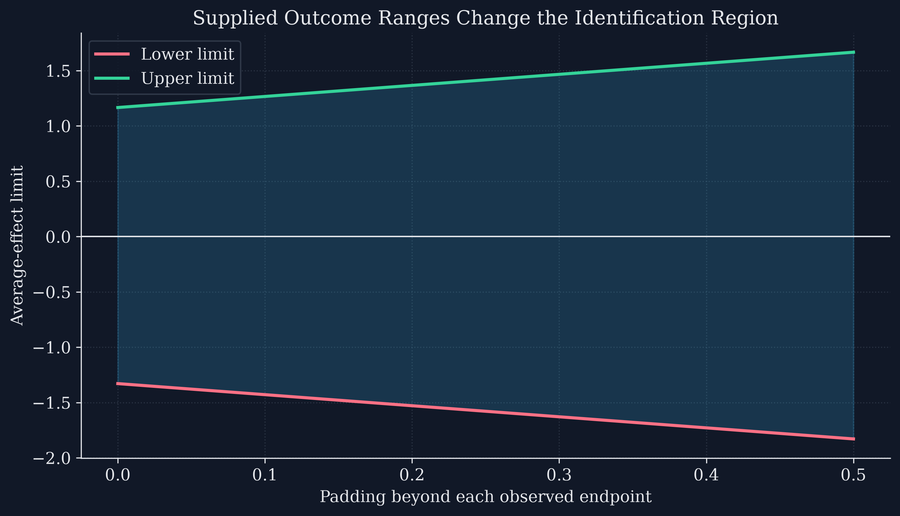

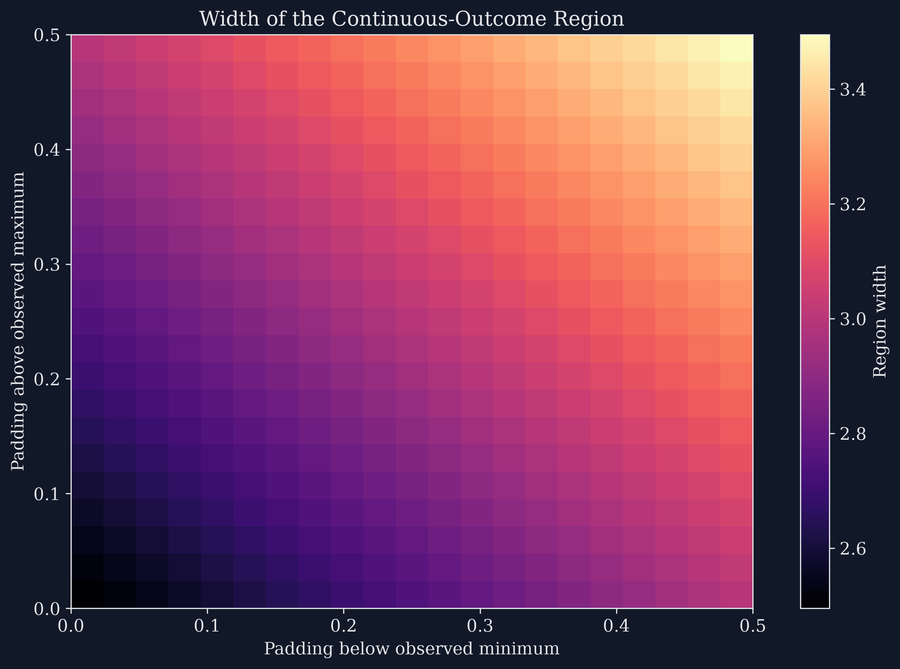

,Lower-end padding,Upper-end padding,Region width,Region midpoint
0,0,0,2.494984,-0.081886
1,0,0.5,2.994984,-0.022886
2,0.5,0,2.994984,-0.140886
3,0.5,0.5,3.494984,-0.081886


,Lower-end padding,Upper-end padding,Region width,Region midpoint
0,0,0,2.494984,-0.081886
1,0,0.5,2.994984,-0.022886
2,0.5,0,2.994984,-0.140886
3,0.5,0.5,3.494984,-0.081886


In [1]:
figure, axis = plt.subplots(figsize=(8.8, 5.0), constrained_layout=True)
axis.plot(padding_frame['Padding beyond observed range'], padding_frame['Lower effect limit'], color=PALETTE['rose'], linewidth=2.2, label='Lower limit')
axis.plot(padding_frame['Padding beyond observed range'], padding_frame['Upper effect limit'], color=PALETTE['green'], linewidth=2.2, label='Upper limit')
axis.fill_between(padding_frame['Padding beyond observed range'], padding_frame['Lower effect limit'], padding_frame['Upper effect limit'], color=PALETTE['cyan'], alpha=0.18)
axis.axhline(0, color=PALETTE['text'], linewidth=1)
axis.set_xlabel('Padding beyond each observed endpoint')
axis.set_ylabel('Average-effect limit')
axis.set_title('Supplied Outcome Ranges Change the Identification Region')
axis.legend()
finish_axis(axis)
save_figure(figure, 'regions_continuous_outcome_padding')
surface_records = []
lower_padding_values = np.linspace(0, 0.5, 21)
upper_padding_values = np.linspace(0, 0.5, 21)
for lower_padding in lower_padding_values:
    for upper_padding in upper_padding_values:
        result = manski_ate_bounds(y_change, d_public, lower=observed_min - lower_padding, upper=observed_max + upper_padding)
        surface_records.append({'Lower-end padding': lower_padding, 'Upper-end padding': upper_padding, 'Region width': result['upper'] - result['lower'], 'Region midpoint': (result['lower'] + result['upper']) / 2})
surface_frame = pd.DataFrame(surface_records)
surface_frame.to_csv(FIGURE_DATA / 'regions_width_surface.csv', index=False)
width_surface = surface_frame.pivot(index='Upper-end padding', columns='Lower-end padding', values='Region width')
figure, axis = plt.subplots(figsize=(8.4, 6.2), constrained_layout=True)
image = axis.imshow(width_surface.to_numpy(), origin='lower', extent=[lower_padding_values.min(), lower_padding_values.max(), upper_padding_values.min(), upper_padding_values.max()], aspect='auto', cmap='magma')
axis.set_xlabel('Padding below observed minimum')
axis.set_ylabel('Padding above observed maximum')
axis.set_title('Width of the Continuous-Outcome Region')
figure.colorbar(image, ax=axis, label='Region width')
save_figure(figure, 'regions_width_surface')
surface_corners = surface_frame.loc[surface_frame['Lower-end padding'].isin([0, 0.5]) & surface_frame['Upper-end padding'].isin([0, 0.5])].reset_index(drop=True)
save_table(surface_corners, 'regions_width_surface_corners', 'Corner cases from the outcome-range surface.', 'tab:cim5-regions-width-corners', fit=True)


## Sign Regions in Regression Sensitivity

For a fixed reduced regression, each pair of partial R-squared values gives an adjusted exposure coefficient. The sign region is

$$
\mathcal S_{+}=\left\{(r_D,r_Y):\widehat\tau(r_D,r_Y)>0\right\},
$$

where $r_D=R^2_{D\sim Z\mid X}$ and $r_Y=R^2_{Y\sim Z\mid D,X}$. The boundary of this set marks combinations that move the adjusted estimate to zero. It is conditional on the linear sensitivity calculation, the reduced estimate, its standard error, and its residual degrees of freedom.

### Sign of the Adjusted Exposure Estimate

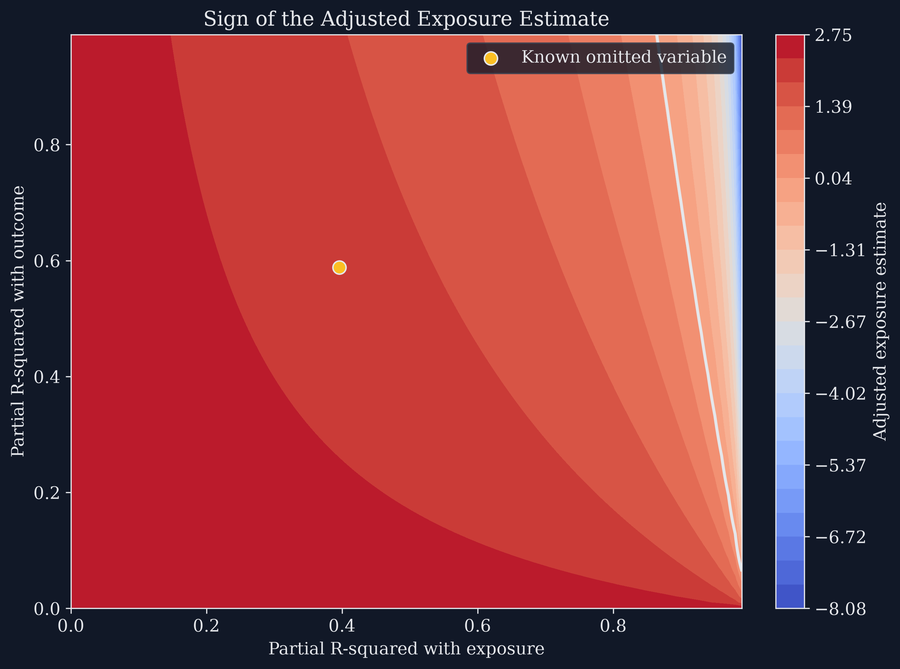

In [2]:
rng = np.random.default_rng(65)
x, z, noise_d, noise_y = rng.normal(size=(4, 500))
d = 0.8 * z + 0.3 * x + noise_d
y = 2 * d + 1.4 * z + x + noise_y
reduced = sm.OLS(y, sm.add_constant(np.column_stack([d, x]))).fit()
full = sm.OLS(y, sm.add_constant(np.column_stack([d, x, z]))).fit()
d_reduced = sm.OLS(d, sm.add_constant(x)).fit()
d_full = sm.OLS(d, sm.add_constant(np.column_stack([x, z]))).fit()
known_r2d = partial_r2(d_reduced, d_full)
known_r2y = partial_r2(reduced, full)

strength_values = np.linspace(0, 0.99, 100)
sign_records = []
for exposure_strength in strength_values:
    for outcome_strength in strength_values:
        estimate = scalar(sensemakr.adjusted_estimate(exposure_strength, outcome_strength, estimate=float(reduced.params[1]), se=float(reduced.bse[1]), dof=int(reduced.df_resid)))
        sign_records.append({"Partial R-squared with exposure": exposure_strength, "Partial R-squared with outcome": outcome_strength, "Adjusted estimate": estimate, "Positive estimate": estimate > 0})
sign_frame = pd.DataFrame(sign_records)
sign_frame.to_csv(FIGURE_DATA / "regions_sensitivity_sign_map.csv", index=False)
sign_surface = sign_frame.pivot(index="Partial R-squared with outcome", columns="Partial R-squared with exposure", values="Adjusted estimate")
figure, axis = plt.subplots(figsize=(8.4, 6.2), constrained_layout=True)
levels = np.linspace(sign_surface.to_numpy().min(), sign_surface.to_numpy().max(), 25)
contours = axis.contourf(strength_values, strength_values, sign_surface.to_numpy(), levels=levels, cmap="coolwarm")
axis.contour(strength_values, strength_values, sign_surface.to_numpy(), levels=[0], colors=[PALETTE["text"]], linewidths=2)
axis.scatter([known_r2d], [known_r2y], color=PALETTE["amber"], edgecolor=PALETTE["text"], s=80, label="Known omitted variable")
axis.set_xlabel("Partial R-squared with exposure")
axis.set_ylabel("Partial R-squared with outcome")
axis.set_title("Sign of the Adjusted Exposure Estimate")
axis.legend()
figure.colorbar(contours, ax=axis, label="Adjusted exposure estimate")
save_figure(figure, "regions_sensitivity_sign_map");



### Grid counts on each side of the zero-estimate boundary

,Region,Grid points
0,Zero or negative adjusted estimate,661
1,Positive adjusted estimate,"9,339"


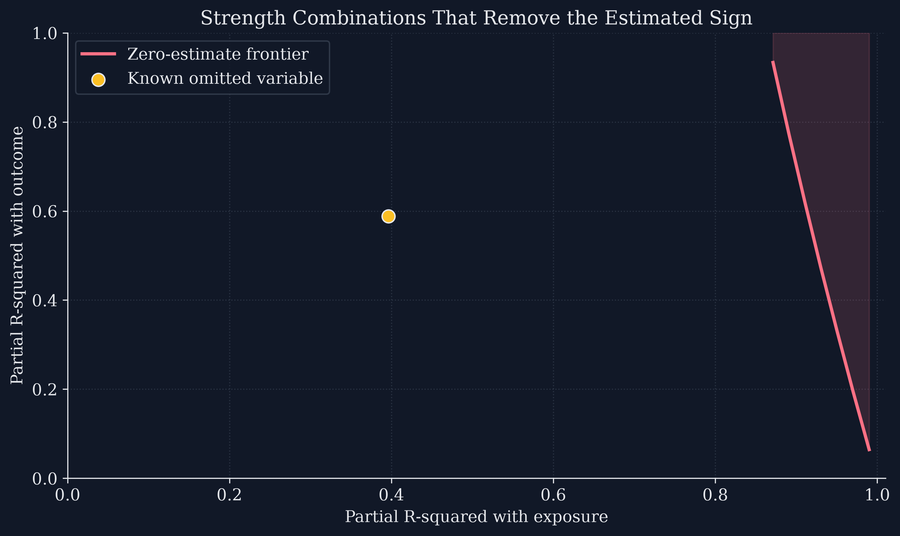

,Partial R-squared with exposure,Minimum partial R-squared with outcome
0,0.871224,0.933514
1,0.89102,0.771982
2,0.910816,0.618378
3,0.930612,0.470721
4,0.950408,0.33
5,0.970204,0.194234
6,0.99,0.064414


,Partial R-squared with exposure,Minimum partial R-squared with outcome
0,0.871224,0.933514
1,0.89102,0.771982
2,0.910816,0.618378
3,0.930612,0.470721
4,0.950408,0.33
5,0.970204,0.194234
6,0.99,0.064414


In [2]:
sign_summary = sign_frame.groupby("Positive estimate", as_index=False).size().rename(columns={"size": "Grid points"})
sign_summary["Region"] = sign_summary["Positive estimate"].map({True: "Positive adjusted estimate", False: "Zero or negative adjusted estimate"})
sign_summary = sign_summary[["Region", "Grid points"]]
save_table(sign_summary, "regions_sensitivity_sign_counts", "Grid counts on each side of the zero-estimate boundary.", "tab:cim5-regions-sign-counts")

frontier_records = []
outcome_grid = np.linspace(0, 0.99, 1000)
for exposure_strength in np.linspace(0.02, 0.99, 50):
    estimates = np.array([scalar(sensemakr.adjusted_estimate(exposure_strength, outcome_strength, estimate=float(reduced.params[1]), se=float(reduced.bse[1]), dof=int(reduced.df_resid))) for outcome_strength in outcome_grid])
    crossing = np.flatnonzero(estimates <= 0)
    frontier_records.append({"Partial R-squared with exposure": exposure_strength, "Minimum partial R-squared with outcome": outcome_grid[crossing[0]] if crossing.size else np.nan})
frontier = pd.DataFrame(frontier_records)
frontier.to_csv(FIGURE_DATA / "regions_zero_estimate_frontier.csv", index=False)
figure, axis = plt.subplots(figsize=(8.8, 5.2), constrained_layout=True)
axis.plot(frontier["Partial R-squared with exposure"], frontier["Minimum partial R-squared with outcome"], color=PALETTE["rose"], linewidth=2.3, label="Zero-estimate frontier")
axis.scatter([known_r2d], [known_r2y], color=PALETTE["amber"], edgecolor=PALETTE["text"], s=85, label="Known omitted variable")
axis.fill_between(frontier["Partial R-squared with exposure"], frontier["Minimum partial R-squared with outcome"], 1, color=PALETTE["rose"], alpha=0.15)
axis.set_xlim(0, 1.01)
axis.set_ylim(0, 1)
axis.set_xlabel("Partial R-squared with exposure")
axis.set_ylabel("Partial R-squared with outcome")
axis.set_title("Strength Combinations That Remove the Estimated Sign")
axis.legend()
finish_axis(axis)
save_figure(figure, "regions_zero_estimate_frontier")

finite_frontier = frontier.dropna().reset_index(drop=True)
frontier_indices = np.linspace(0, len(finite_frontier) - 1, min(10, len(finite_frontier)), dtype=int)
frontier_table = finite_frontier.iloc[np.unique(frontier_indices)].reset_index(drop=True)
save_table(frontier_table, "regions_zero_estimate_frontier_points", "Selected finite points on the zero-estimate frontier.", "tab:cim5-regions-zero-frontier", fit=True)

## Reading the Regions Together

The bounded-outcome region and the regression sensitivity surface answer different questions. The first varies missing potential outcomes within a supplied outcome range and does not assume treatment exchangeability. The second starts from a linear regression and varies the conditional strength of one omitted variable. A narrow regression interval does not narrow the worst-case identification region, and a wide identification region does not determine which omitted-variable strengths are plausible.

In [3]:
integration_checks = pd.DataFrame([
    {"Statement": "Binary public outcome lies inside supplied limits", "Pass": y_binary.min() >= 0 and y_binary.max() <= 1},
    {"Statement": "Released binary limits equal group decomposition", "Pass": np.isclose(released_binary["lower"], decomposition.loc[0, "Total"]) and np.isclose(released_binary["upper"], decomposition.loc[1, "Total"])},
    {"Statement": "Continuous-region width equals supplied outcome range", "Pass": np.allclose(padding_frame["Region width"], padding_frame["Upper outcome limit"] - padding_frame["Lower outcome limit"])},
    {"Statement": "Known omitted-variable adjustment recovers full coefficient", "Pass": np.isclose(scalar(sensemakr.adjusted_estimate(known_r2d, known_r2y, estimate=float(reduced.params[1]), se=float(reduced.bse[1]), dof=int(reduced.df_resid))), full.params[1])},
])
assert integration_checks["Pass"].all()
save_table(integration_checks, "regions_integration_checks", "Checks linking the identification and sensitivity calculations.", "tab:cim5-regions-integration-checks", fit=True)

section_summary = pd.DataFrame([
    {"Object": "Worst-case identification region", "Changes when": "The supplied outcome limits change", "Does not establish": "A point effect or confidence interval"},
    {"Object": "Regression sensitivity surface", "Changes when": "The two partial R-squared values change", "Does not establish": "That a hidden variable with those strengths exists"},
    {"Object": "Observed-covariate benchmark", "Changes when": "A measured baseline variable is omitted", "Does not establish": "A bound on all unmeasured confounding"},
    {"Object": "Public county calculation", "Changes when": "The declared outcome, group, or controls change", "Does not establish": "A causal minimum-wage effect"},
])
save_table(section_summary, "regions_section_summary", "How to interpret the chapter's identification and sensitivity regions.", "tab:cim5-regions-section-summary", fit=True)

,Statement,Pass
0,Binary public outcome lies inside supplied limits,Pass
1,Released binary limits equal group decomposition,Pass
2,Continuous-region width equals supplied outcom...,Pass
3,Known omitted-variable adjustment recovers ful...,Pass


,Object,Changes when,Does not establish
0,Worst-case identification region,The supplied outcome limits change,A point effect or confidence interval
1,Regression sensitivity surface,The two partial R-squared values change,That a hidden variable with those strengths ex...
2,Observed-covariate benchmark,A measured baseline variable is omitted,A bound on all unmeasured confounding
3,Public county calculation,"The declared outcome, group, or controls change",A causal minimum-wage effect


,Object,Changes when,Does not establish
0,Worst-case identification region,The supplied outcome limits change,A point effect or confidence interval
1,Regression sensitivity surface,The two partial R-squared values change,That a hidden variable with those strengths ex...
2,Observed-covariate benchmark,A measured baseline variable is omitted,A bound on all unmeasured confounding
3,Public county calculation,"The declared outcome, group, or controls change",A causal minimum-wage effect
